# 21.2 Key 🔑

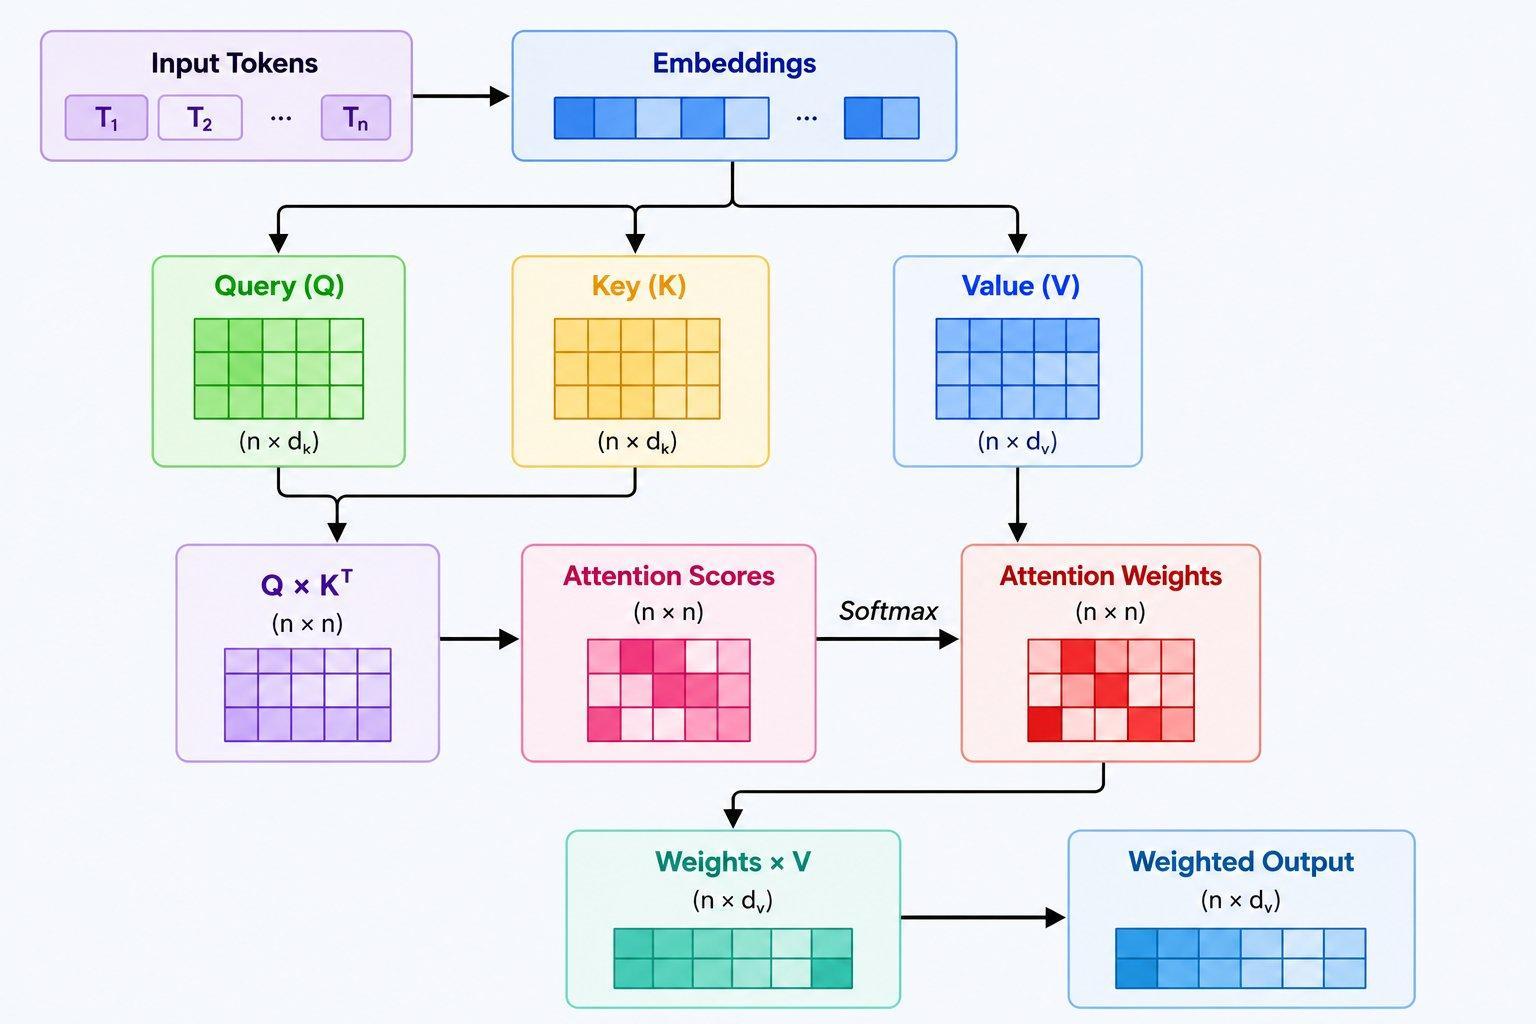

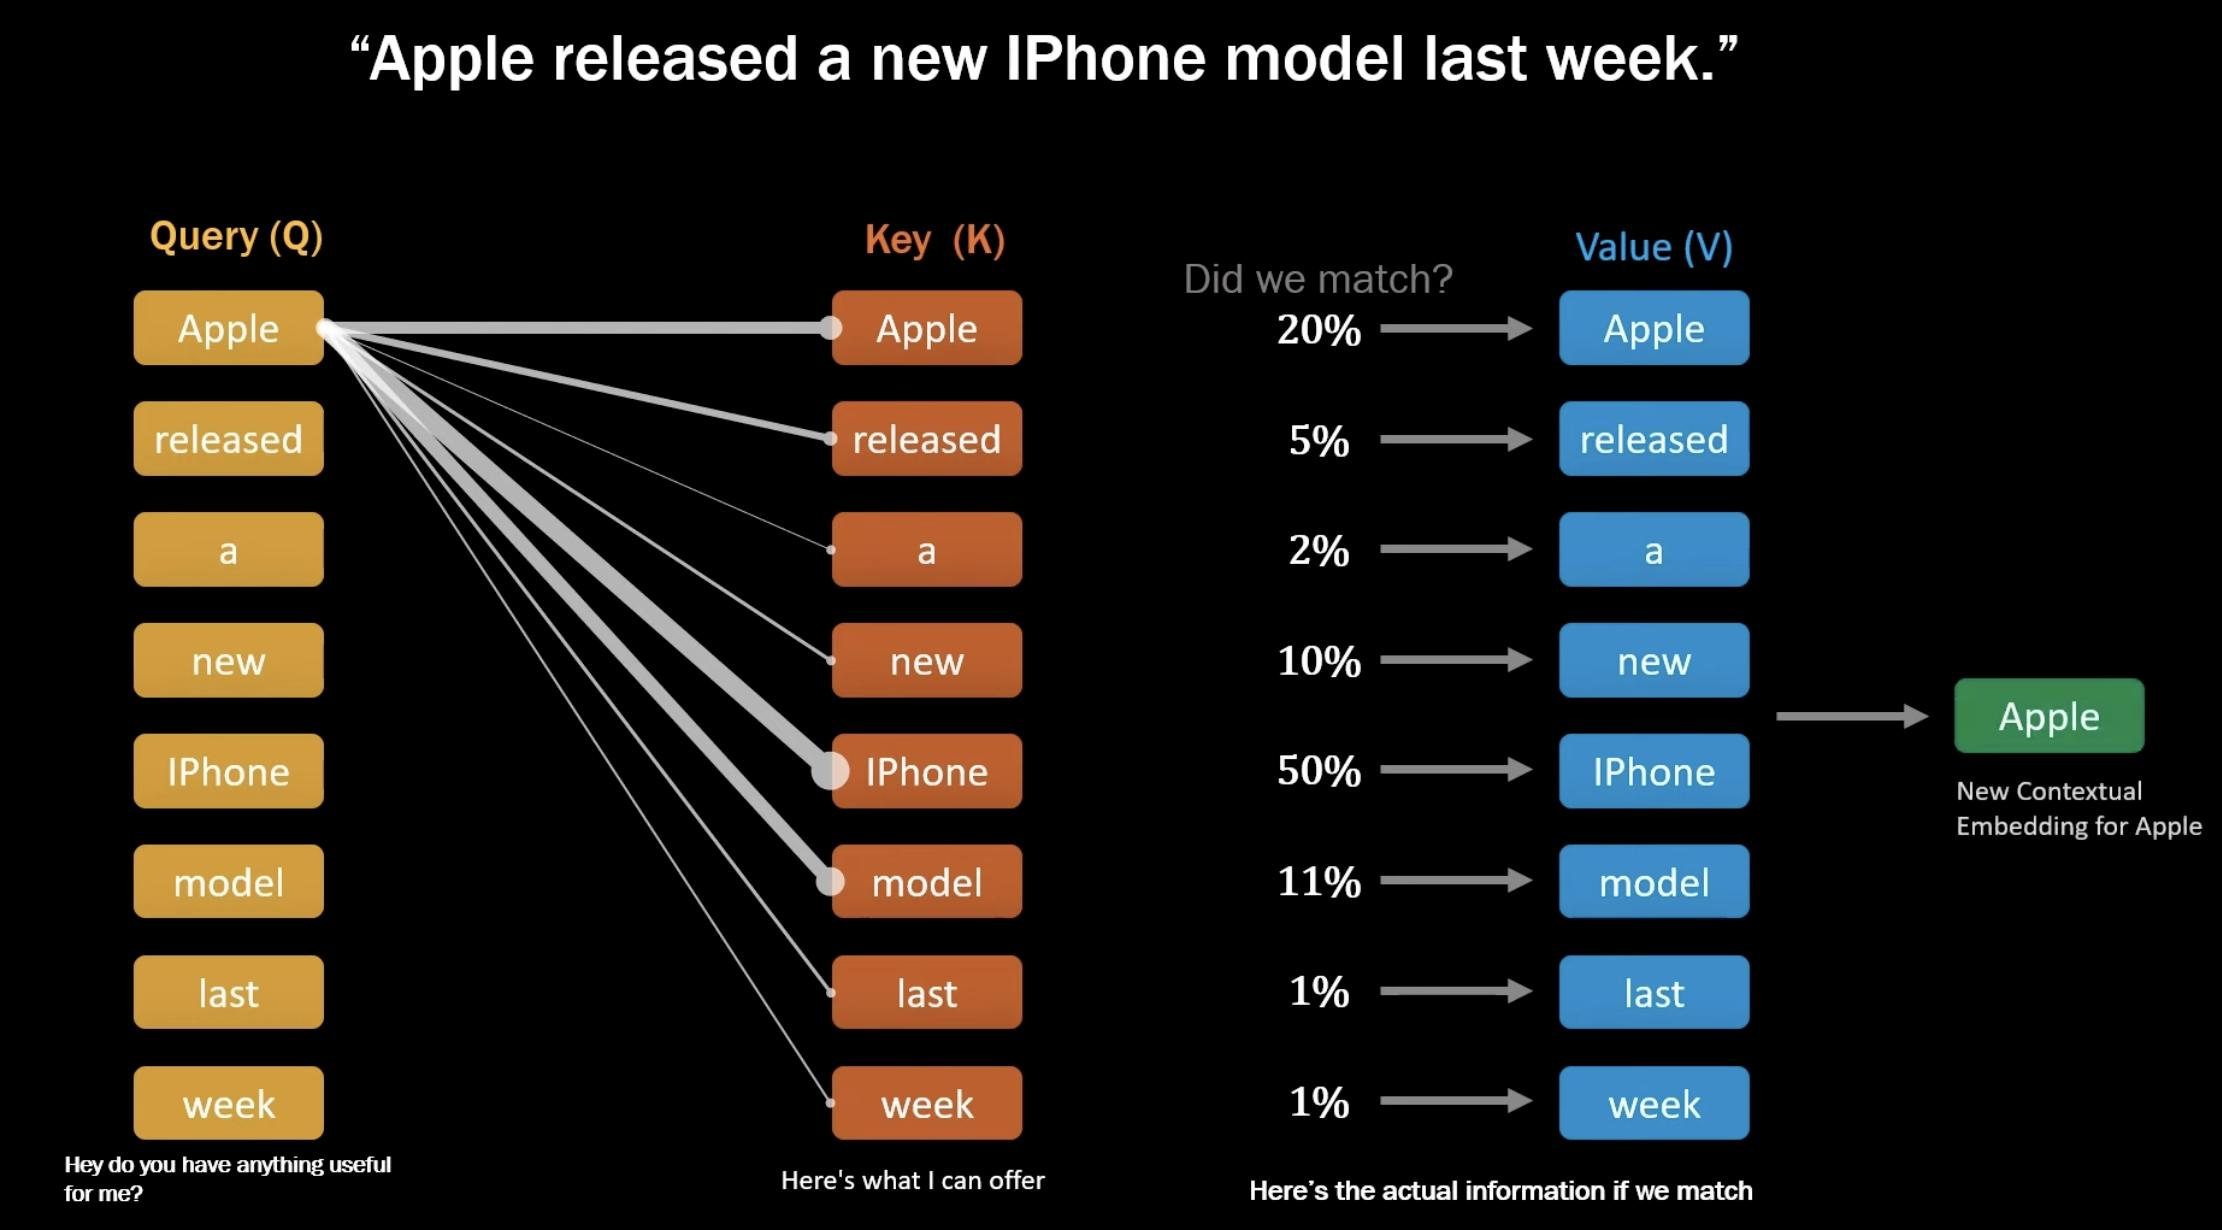
The **Key (K)** is the representation that tells the attention mechanism **what a token can be matched for**.

The syllabus places **Key immediately after Query**, because attention fundamentally works by comparing:

$$
\boxed{\text{Query} \leftrightarrow \text{Key}}
$$

and then using the resulting weights to retrieve information from the **Values**.    syllabus(20261018-070535)

---

## 1. Intuition — What is a Key?

Think of the **Key** as an **index or label describing what information a token offers for matching**.

A useful mental model:

> 🔎 **Query:** “What am I looking for?”
> 🔑 **Key:** “What kind of information do I represent?”
> 📦 **Value:** “Here is the actual information.”

The attention mechanism compares a query against **all relevant keys** and determines which ones are more relevant. The standard attention formulation uses these compatibility scores to determine the weights applied to values.

---

# 2. Where does the Key come from?

A token's hidden representation is projected into a Key vector using a learned matrix:

$$
\boxed{K = XW_K}
$$

For an individual token:

$$
\boxed{k_i=x_iW_K}
$$

where:

- $x_i$ = token representation
- $W_K$ = learned key-projection matrix
- $k_i$ = resulting key vector

So the Key is **not simply the original word embedding**.

It is a **learned representation optimized for attention matching**.

In Transformer attention, separate learned projections produce $Q$, $K$, and $V$. 

---

# 3. Why do we need Keys?

Suppose the input is:

> **"The cat sat on the mat."**

Imagine the decoder is currently generating a word that requires information related to **"cat."**

Its Query might represent something like:

> “I need information about the entity performing the action.”

The encoder has produced Keys for:

| Token | Key conceptually represents       |
| ----- | --------------------------------- |
| The   | determiner-related information    |
| cat   | entity / noun-related information |
| sat   | action / verb-related information |
| on    | relation                          |
| the   | determiner                        |
| mat   | location/object                   |

The decoder compares its Query against every Key:

$$
q_t\cdot k_1,\quad q_t\cdot k_2,\quad \dots,\quad q_t\cdot k_T
$$

If the Query matches the Key for **cat** strongly, that position receives a larger attention score.

---

# 4. Query–Key Matching 🎯

This is the most important relationship to understand:

$$
\boxed{
\text{Query determines what we are searching for}
}
$$

$$
\boxed{
\text{Key determines what each position can be matched against}
}
$$

Then:

$$
\boxed{
\text{Query} \cdot \text{Key} \rightarrow \text{relevance score}
}
$$

For scaled dot-product attention:

$$
\text{Scores} = \frac{QK^T}{\sqrt{d_k}}
$$

The resulting scores are converted into attention weights using softmax:

$$
\alpha = \text{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)
$$

Then those weights are applied to $V$.


So the overall flow is:
```text
Query Q
   │
   │ compare
   ▼
Keys K
   │
   ▼
Attention Scores
   │
   ▼
Softmax
   │
   ▼
Attention Weights
   │
   │ applied to
   ▼
Values V
   │
   ▼
Context / Attention Output
```

---

# 5. Key ≠ Value ⚠️

This distinction is **very important for interviews and Transformer implementation**.

A Key answers:

> **"How should this token be matched?"**

A Value answers:

> **"What information should this token contribute if selected?"**

Therefore:

$$
\boxed{K \neq V}
$$

even though both are generated from the same underlying representation.

For example:
```text
Encoder hidden state x
        │
        ├── W_K ──> Key
        │
        └── W_V ──> Value
```

The separate projections allow the model to learn that:

- one representation is useful for **finding** information,
- another is useful for **transmitting** information.

That separation is one reason Transformers use independent $W_Q,W_K,W_V$ projections. 

---

# 6. Key in Cross-Attention

This is particularly important for your current **NLP/Seq2Seq** context.

In **cross-attention**:

$$
\boxed{Q \leftarrow Decoder}
$$

$$
\boxed{K,V \leftarrow Encoder}
$$

So:
```text
             ENCODER
        "The cat eats fish"
               │
          ┌────┴────┐
          ▼         ▼
          K         V
          │         │
          │         │
          └────┬────┘
               │
          Attention
               ▲
               │
               Q
               │
            DECODER
```

The decoder's Query asks:

> “Which information from the source sentence is relevant right now?”

The encoder's Keys provide the candidates against which that Query is matched.

This is the fundamental information-routing mechanism of encoder-decoder attention. 

---

# 7. Key in Self-Attention

In **self-attention**, the situation is different:

$$
Q=XW_Q
$$

$$
K=XW_K
$$

$$
V=XW_V
$$

All three originate from the **same sequence**, although they serve different roles. 

For example:
```text
"The cat eats fish"

       X
       │
 ┌─────┼─────┐
 ▼     ▼     ▼
 Q     K     V
 │     │     │
 └──┬──┘     │
    │        │
    ▼        ▼
 QKᵀ        V
    │
    ▼
 Softmax
    │
    ▼
Attention Weights × V
```

---

# 8. A subtle but important point 🧠

Don't interpret the Key too literally as a human-readable label.

A Key is **not** something like:
```text
cat → "animal"
```

Instead, it is a learned numerical vector:

$$
k_i \in \mathbb{R}^{d_k}
$$

The model learns the projection matrix $W_K$ during training.

So when we say:

> “The Key tells us what a token offers”

that is an **intuition**, not a literal semantic label.

The actual Key is simply a vector optimized to participate effectively in attention matching.

---

# 9. Query–Key–Value: The complete mental model

This is the mental model I want you to retain:

### 🔎 Query

**What am I looking for?**

### 🔑 Key

**What information can I be matched for?**

### 📦 Value

**What information should I actually provide?**

Therefore:

$$
\boxed{
Q \times K \rightarrow \text{relevance} \rightarrow \text{weights} \rightarrow V
}
$$

Or, even shorter:

> **Q and K decide WHERE to look. V provides WHAT to take.**

That's one of the most useful Transformer intuitions you can carry forward.

---

## 10. Shape intuition

Suppose:

- sequence length $=T$
- model dimension $=d_{\text{model}}$
- key dimension $=d_k$

Then:

$$
X \in \mathbb{R}^{T\times d_{\text{model}}}
$$

and:

$$
W_K\in\mathbb{R}^{d_{\text{model}}\times d_k}
$$

Therefore:

$$
\boxed{K=XW_K}
$$

has shape:

$$
\boxed{K\in\mathbb{R}^{T\times d_k}}
$$

Then:

$$
QK^T
$$

has shape:

$$
(T\times d_k)(d_k\times T)
=
\boxed{T\times T}
$$

This $T\times T$ matrix contains the pairwise attention scores.

You'll use this shape reasoning heavily when we implement attention in PyTorch.

---

# 🎯 Must Know

| Concept         | Remember                                           |
| --------------- | -------------------------------------------------- |
| **Key**         | Representation used for matching against Queries   |
| Source          | $K=XW_K$                                           |
| Matching        | $QK^T$                                             |
| Purpose         | Determines relevance / attention scores            |
| Cross-attention | $K,V$ come from encoder                            |
| Self-attention  | $Q,K,V$ come from same sequence                    |
| Key vs Value    | Key helps **find**; Value provides **information** |

### Interview question

**Q: What is the role of the Key in attention?**

> The Key is a learned representation of each token that is compared with a Query to compute an attention/relevance score. The resulting attention weights determine how strongly the corresponding Value contributes to the output.

---

## What you should remember 🧠

1. **Key = representation used for matching.**
2. $K=XW_K$.
3. **Queries are compared against Keys.**
4. $QK^T$ produces attention scores.
5. **Keys decide relevance; Values carry the retrieved information.**
6. In cross-attention, **K and V come from the encoder, Q comes from the decoder**.

---